# 04 · Modelação · Cover Shadow Value (CSV)

Fase 4 do CRISP-DM (capítulo 7 do TFM). Dados: **SkillCorner Open Data** (licença MIT), com body pose.
Jogo de desenvolvimento: 1925299, Brisbane Roar – Perth Glory (21/12/2024). Segundo jogo:
1996435, Sydney FC – Adelaide United (01/02/2025), calculado sem alterar nenhum parâmetro.

**O que se calcula:** em cada instante de uma posse, o valor das linhas de passe que as sombras de
cobertura dos defesas fecham (*ameaça negada*), repartido entre eles.

| Passo | Decisão | Código |
|---|---|---|
| Parâmetros | A1–A4, A11 | `metrica/parametros.py` |
| 1. Linhas de passe e perigo (ganho de xT); fora de jogo e cruzamentos ficam de fora | D7, D15, D26, D27 | `metrica/linhas.py`, `metrica/xt.py`, `metrica/fora_de_jogo.py`, `metrica/cruzamento.py` |
| 2. Marcação (sem guarda-redes; pressão não é marcação; continuidade; entrada a 4 m, lado a lado conta) | D5, D14, D20, D25, D28, D29, D33 | `metrica/marcacao.py`, `metrica/pipeline.py` |
| 3. Defesas que podem afetar cada linha; linhas excluídas | D13, D18 | `metrica/linhas.py` |
| 4. Sombra (cone geométrico orientado pelo tronco; corpo tapa a linha rente, de forma gradual) | D2–D4, D10, D19, D30, D34 | `metrica/sombra.py`, `metrica/linhas.py` |
| 5. Probabilidade de o passe chegar (alcance gradual) | D16, D19 | `metrica/chegada.py` |
| 6. Ameaça negada e repartição (Shapley) | D8, D9 | `metrica/chegada.py` |
| 7. Agregação por lance, posse e jogador; por zona do campo e fase defensiva | D6, D17, D32 | `metrica/agregacao.py` |

Esta é a **terceira versão** (v3) do cálculo: incorpora as decisões D25–D31, saídas da revisão de 15 lances por um
treinador, e D33–D34, saídas da segunda revisão (ver `DECISOES.md`). A primeira versão está guardada no commit
"avaliação v1, antes da revisão" (9f56824) e a segunda (D25–D31) no commit 14d6d0e.

A primeira parte percorre **um único lance**, passo a passo; a segunda mostra o jogo inteiro; a terceira
põe os dois jogos lado a lado.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Polygon
from mplsoccer import Pitch

from footy.ingest import skillcorner as sc
from footy.metrics.orientacao import vetor
from footy.paths import PROJECTS, output_dir
from footy.viz.theme import apply_theme, load_brand

sys.path.insert(0, str(PROJECTS / "cover_shadow"))  # para importar o código do projeto

In [2]:
from calcular_metrica import caminhos
from metrica import agregacao
from metrica.linhas import avaliar_frame, pode_afetar, recetores_com_valor
from metrica.parametros import (
    PADRAO_V3 as PADRAO,  # a v3: as secções 1 a 4.1 descrevem-na; a v3.1 está na 4.2
)
from metrica.pipeline import carregar_tabela, preparar_defesas
from metrica.xt import sentido_de_ataque

brand = load_brand()
apply_theme(brand)
FONTE = "SkillCorner Open Data (MIT)"
SAIDA = output_dir("cover_shadow")
JOGO = sc.JOGO_PADRAO
JOGO_2 = 1996435

In [3]:
def credito(fig, extra="", ajustar=True):
    """Crédito da fonte no fundo da figura; `ajustar` abre espaço para ele nos gráficos simples."""
    if ajustar:
        fig.tight_layout(rect=(0, 0.06, 1, 1))
    texto = (extra + " · " if extra else "") + brand.credit(FONTE)
    fig.text(0.5, 0.01, texto, ha="center", va="bottom", color=brand.colors["text_muted"], fontsize=9)


def pt(valor, casas=1):
    """Número com vírgula decimal, para o texto."""
    return f"{valor:.{casas}f}".replace(".", ",")


def novo_campo(comprimento, largura, figsize=(11, 7.4)):
    campo = Pitch(pitch_type="skillcorner", pitch_length=comprimento, pitch_width=largura,
                  pitch_color=brand.colors["pitch"], line_color=brand.colors["lines"], linewidth=1.2)
    return campo.draw(figsize=figsize)


def jogo_completo(jogo):
    """Tudo o que o notebook usa de um jogo: dados, defesas, resultados guardados e nomes."""
    match = sc.ler_match(jogo)
    tabela = carregar_tabela(jogo)
    linhas_p, atrib_p = caminhos(jogo)
    return {
        "jogo": jogo, "match": match, "tabela": tabela,
        "defesas": preparar_defesas(tabela, match, PADRAO),
        "linhas": pd.read_parquet(linhas_p), "atribuicoes": pd.read_parquet(atrib_p),
        "campo": sc.dimensoes_campo(match),
        "jogadores": pd.DataFrame([{"jogador": p["id"], "nome": p["short_name"], "equipa": p["team_id"],
                                     "posicao": p["player_role"]["acronym"]} for p in match["players"]]),
        "equipas": {match["home_team"]["id"]: match["home_team"]["short_name"],
                    match["away_team"]["id"]: match["away_team"]["short_name"]},
    }


J = jogo_completo(JOGO)
match, comprimento, largura = J["match"], *J["campo"]
nome = J["jogadores"].set_index("jogador")["nome"].to_dict()
print(f"{match['home_team']['short_name']} – {match['away_team']['short_name']}: "
      f"{J['tabela']['frame'].nunique()} frames alinhados em posse, {len(J['linhas'])} linhas de passe")

Brisbane FC – Perth Glory: 8915 frames alinhados em posse, 89150 linhas de passe


## 1. Parâmetros

Todos os valores estão num só objeto (`metrica/parametros.py`). São valores de partida: a fase 5
(avaliação) testa-os por sensibilidade. Nenhum está fixo no código dos passos seguintes.

In [4]:
pd.DataFrame([
    ("Ângulo do cone (total)", f"{PADRAO.angulo_cone:.0f}°", "A2 · a definição original"),
    ("Comprimento do cone", f"{PADRAO.comprimento_cone:.0f} m", "A3 · limite do passe por cima (D4)"),
    ("Largura do cone junto ao corpo", f"{PADRAO.largura_junto_ao_corpo:.1f} m", "A4 · D3"),
    ("Tempo de reação do defesa", f"{PADRAO.tempo_reacao:.1f} s", "D21 · Spearman (2018)"),
    ("Velocidade do defesa", f"{PADRAO.velocidade_defesa:.1f} m/s", "D21 · Spearman (2018)"),
    ("Velocidade da bola", f"{PADRAO.velocidade_bola:.0f} m/s", "D21 · Shaw (Friends of Tracking)"),
    ("Incerteza no tempo de interceção", f"{PADRAO.incerteza_tempo:.2f} s", "D21 · Shaw (Friends of Tracking)"),
    ("Marcação: distância ao atacante", f"{PADRAO.distancia_marcacao:.0f} m", "A1 · D14, D33"),
    ("Marcação: tolerância no lado da baliza", f"{PADRAO.tolerancia_lado_baliza:.0f} m", "A1 · D33"),
    ("Marcação: tempo mínimo", f"{PADRAO.tempo_marcacao:.1f} s", "A1 · D14"),
    ("Marcação: distância de saída", f"{PADRAO.distancia_saida_marcacao:.0f} m", "A11 · D29"),
    ("Pressão: distância ao portador", f"{PADRAO.distancia_pressao:.0f} m", "A11 · D28"),
    ("Bloqueio pelo corpo: totalmente tapada até", f"{PADRAO.bloqueio_pleno:.1f} m", "A11 · D34"),
    ("Bloqueio pelo corpo: sem efeito a partir de", f"{PADRAO.bloqueio_nulo:.1f} m", "A11 · D34"),
    ("Cruzamento: passe curto até", f"{PADRAO.comprimento_passe_curto:.0f} m", "A11 · D27"),
    ("Cruzamento: avanço máximo de um passe atrasado", f"{PADRAO.avanco_maximo_atrasado:.0f} m", "A11 · D27"),
], columns=["Parâmetro", "Valor", "Origem"]).style.hide(axis="index")

Parâmetro,Valor,Origem
Ângulo do cone (total),60°,A2 · a definição original
Comprimento do cone,10 m,A3 · limite do passe por cima (D4)
Largura do cone junto ao corpo,2.0 m,A4 · D3
Tempo de reação do defesa,0.7 s,D21 · Spearman (2018)
Velocidade do defesa,5.0 m/s,D21 · Spearman (2018)
Velocidade da bola,15 m/s,D21 · Shaw (Friends of Tracking)
Incerteza no tempo de interceção,0.45 s,D21 · Shaw (Friends of Tracking)
Marcação: distância ao atacante,4 m,"A1 · D14, D33"
Marcação: tolerância no lado da baliza,1 m,A1 · D33
Marcação: tempo mínimo,1.0 s,A1 · D14


## 2. Um lance, passo a passo

O lance escolhido é um frame (0,2 s) em que há linhas avaliadas e excluídas, um defesa a marcar e
pelo menos uma linha com duas sombras, para que todos os passos tenham algo para mostrar. A seleção
usa só estas condições, escolhendo entre os que as cumprem o de maior ameaça negada.

In [5]:
def escolher_lance(J):
    linhas, defesas = J["linhas"], J["defesas"]
    por_frame = linhas.groupby("frame").agg(
        excluidas=("excluida", "sum"), avaliadas=("excluida", lambda s: (~s).sum()),
        max_sombras=("n_sombras", "max"), negada=("ameaca_negada", "sum"))
    marcam = defesas.groupby("frame")["a_marcar"].sum()
    bons = por_frame[(por_frame["excluidas"] > 0) & (por_frame["avaliadas"] >= 4)
                     & (por_frame["max_sombras"] >= 2) & (marcam.reindex(por_frame.index) > 0)]
    return int(bons["negada"].idxmax())


FRAME = escolher_lance(J)
jogadores_frame = J["tabela"][J["tabela"]["frame"] == FRAME]
defesas_frame = J["defesas"][J["defesas"]["frame"] == FRAME].reset_index(drop=True)
primeiro = jogadores_frame.iloc[0]
sentido = sentido_de_ataque(match, primeiro["equipa_com_bola"], primeiro["periodo"])
origem, recetores = recetores_com_valor(jogadores_frame, sentido, comprimento, largura, PADRAO)
linhas_frame, atrib_frame = avaliar_frame(origem, recetores, defesas_frame, PADRAO)
portador = primeiro["portador"]
com_bola = J["equipas"][primeiro["equipa_com_bola"]]
print(f"Frame {FRAME} · {primeiro['periodo']}.ª parte · posse de {com_bola} · portador {nome[portador]} · "
      f"ataca para {'x positivo' if sentido > 0 else 'x negativo'}")

Frame 56534 · 2.ª parte · posse de Brisbane FC · portador Walid Shour · ataca para x positivo


In [6]:
COR_ATAQUE, COR_DEFESA = brand.colors["secondary"], brand.colors["text"]
JANELA = 22  # metros à volta do portador, para o lance se ler bem


def base(titulo, legenda=None):
    """Campo recortado à volta do lance, com jogadores e portador desenhados."""
    fig, ax = novo_campo(comprimento, largura, figsize=(11, 7.2))
    campo_x = (max(-comprimento / 2, origem[0] - JANELA - 8), min(comprimento / 2, origem[0] + JANELA + 8))
    campo_y = (max(-largura / 2, origem[1] - JANELA), min(largura / 2, origem[1] + JANELA))
    ax.set_xlim(campo_x)
    ax.set_ylim(campo_y)
    ataque = jogadores_frame[jogadores_frame["equipa"] == primeiro["equipa_com_bola"]]
    ax.scatter(ataque["x"], ataque["y"], s=150, color=COR_ATAQUE, zorder=4, edgecolor=brand.colors["background"])
    ax.scatter(defesas_frame["x"], defesas_frame["y"], s=150, color=COR_DEFESA, zorder=4,
               edgecolor=brand.colors["background"])
    ax.scatter([origem[0]], [origem[1]], s=420, facecolor="none", edgecolor=brand.colors["primary"], lw=2.5, zorder=5)
    for _, r in jogadores_frame.iterrows():
        ax.annotate(nome[r["jogador"]].split(". ")[-1], (r["x"], r["y"]), xytext=(0, 11), textcoords="offset points",
                    ha="center", fontsize=7.5, color=brand.colors["text_muted"], zorder=6)
    ax.set_title(titulo, loc="left", color=brand.colors["text"], fontsize=13)
    if legenda:
        ax.text(0.01, 0.015, legenda, transform=ax.transAxes, fontsize=9, color=brand.colors["text_muted"], zorder=7)
    return fig, ax


def guardar(fig, nome_ficheiro, extra=""):
    credito(fig, extra or f"Frame {FRAME} · {com_bola} com bola")
    fig.savefig(SAIDA / f"fase4_{nome_ficheiro}.png", dpi=150, facecolor=brand.colors["background"])
    plt.show()

### 2.1 Linhas de passe e perigo (D7, D15)

Do portador (círculo laranja) sai uma linha reta para cada colega, incluindo as que estão fechadas.
O perigo de cada linha é o ganho de xT na grelha pública de Karun Singh (12 × 8, a mesma que o
`socceraction` carrega): xT do destino menos xT do portador, só a parte positiva. A grelha é lida
com o campo virado para o sentido de ataque da equipa, porque o sentido troca ao intervalo.

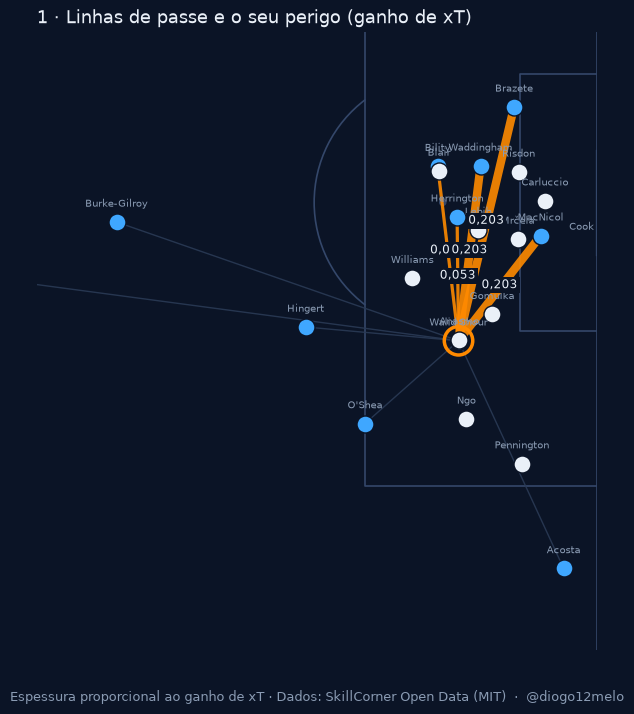

In [7]:
fig, ax = base("1 · Linhas de passe e o seu perigo (ganho de xT)")
maximo = max(recetores["valor_xt"].max(), 1e-9)
for _, r in recetores.iterrows():
    ax.plot([origem[0], r["x"]], [origem[1], r["y"]], color=brand.colors["primary"] if r["valor_xt"] > 0 else brand.colors["neutral"],
            lw=1 + 5 * r["valor_xt"] / maximo, alpha=0.9, zorder=2)
    if r["valor_xt"] > 0:
        ax.annotate(pt(r["valor_xt"], 3), ((origem[0] + r["x"]) / 2, (origem[1] + r["y"]) / 2), fontsize=8.5,
                    color=brand.colors["text"], ha="center", zorder=6,
                    bbox={"facecolor": brand.colors["background"], "edgecolor": "none", "pad": 1.5})
guardar(fig, "1_linhas", "Espessura proporcional ao ganho de xT")

### 2.2 Marcação (D5, D14, D20, D25, D28, D29, D33)

**Começa** a marcar o defesa que tem um atacante a menos de 4 m (D33), está do lado da baliza em relação a
ele (lado a lado também conta, com 1 m de tolerância, D33) e é o defesa mais próximo desse atacante há pelo menos 1 s. **Continua** a marcar até se afastar
a mais de 5 m (D29), para a marcação não ligar e desligar a cada passo. Quem marca fica de fora da
sombra nesse momento. O corpo não entra na regra. O portador da bola não conta como atacante mais
próximo (D20) e quem está a menos de 4 m do portador está a pressionar, nunca a marcar (D28): é
avaliado pela sombra que faz. O guarda-redes não projeta sombra nem marca (D25).


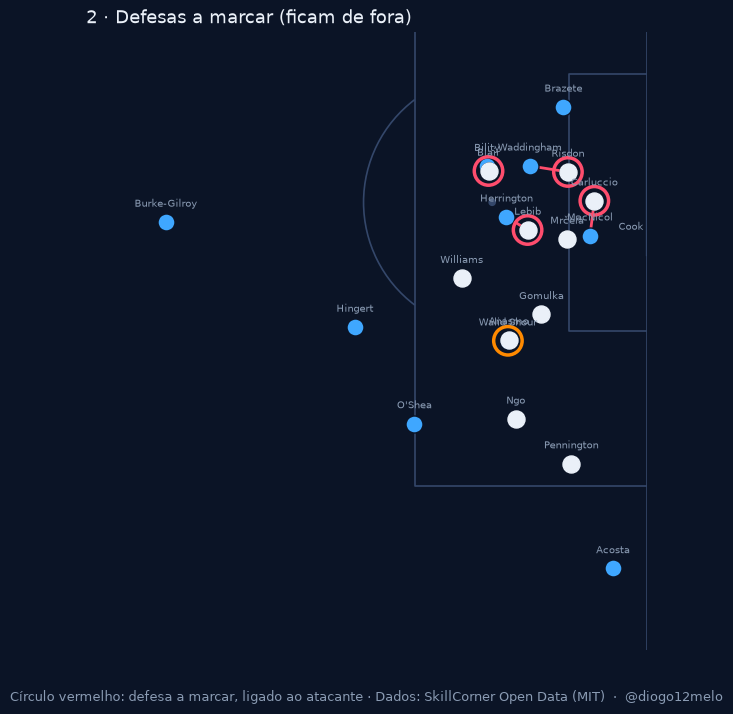

,Defesa,Distância (m),Tempo (s)
0,J. Risdon,2.7,1.0
3,N. Blair,0.4,1.0
6,J. Carluccio,2.5,1.0
7,A. Lebib,1.8,1.0


In [8]:
fig, ax = base("2 · Defesas a marcar (ficam de fora)")
marcam = defesas_frame[defesas_frame["a_marcar"]]
ax.scatter(defesas_frame["x"], defesas_frame["y"], s=150, color=COR_DEFESA, zorder=4)
for _, d in marcam.iterrows():
    ax.plot([d["x"], d["atacante_x"]], [d["y"], d["atacante_y"]], color=brand.colors["save"], lw=2, zorder=3)
    ax.scatter([d["x"]], [d["y"]], s=420, facecolor="none", edgecolor=brand.colors["save"], lw=2.5, zorder=5)
tabela_marcacao = marcam[["jogador", "dist_atacante", "persistencia_s"]].assign(
    jogador=lambda t: t["jogador"].map(nome))
guardar(fig, "2_marcacao", "Círculo vermelho: defesa a marcar, ligado ao atacante")
tabela_marcacao.rename(columns={"jogador": "Defesa", "dist_atacante": "Distância (m)", "persistencia_s": "Tempo (s)"}).round(1)

### 2.3 Quem pode afetar cada linha; linhas excluídas (D13, D18, D26, D27)

Há três razões para uma linha **não se avaliar**, todas contadas à parte e por esta ordem:
1. **Fora de jogo (D26):** o colega está em posição de fora de jogo, por isso a linha não é um passe válido.
2. **Cruzamento (D27):** o portador está num corredor lateral do terço ofensivo (etiquetas da SkillCorner) e
   a linha vai para dentro da grande área sem ser passe atrasado nem curto (até 12 m).
3. **Sem pose (D13):** algum defesa que podia afetar a linha não tem pose.

Um defesa que não marca pode afetar uma linha se estiver a menos de *comprimento do cone + metade da
largura junto ao corpo* (11 m) da linha. Defesas sem pose mais longe não excluem nada.


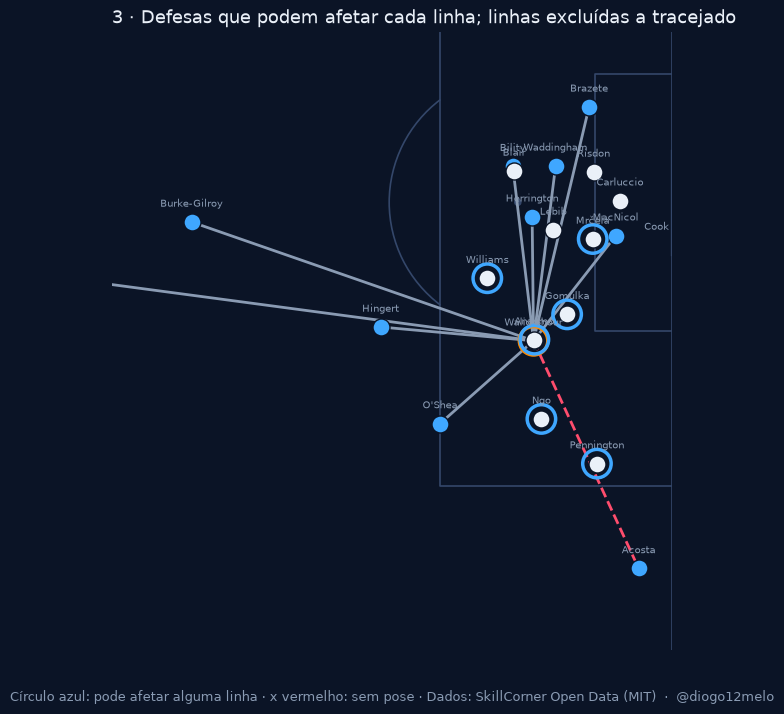

1 de 10 linhas excluídas neste frame: {'sem_pose': 0, 'fora_de_jogo': 1, 'cruzamento': 0, 'mais_de_35m': 0}


,recetor,valor_xt,n_podem_afetar,excluida,motivo
0,M. Freke,0.000,6,False,
1,J. O'Shea,0.000,6,False,
2,J. Hingert,0.000,6,False,
3,H. Bility,0.053,6,False,
4,N. Acosta,0.000,6,True,fora_de_jogo
5,A. Burke-Gilroy,0.000,6,False,
6,T. Waddingham,0.203,6,False,
7,Q. MacNicol,0.203,6,False,
8,L. Herrington,0.053,6,False,
9,J. Brazete,0.203,6,False,


In [9]:
fig, ax = base("3 · Defesas que podem afetar cada linha; linhas excluídas a tracejado")
pode_alguma = np.zeros(len(defesas_frame), dtype=bool)
for _, r in linhas_frame.merge(recetores, on=["recetor", "valor_xt"]).iterrows():
    afeta = pode_afetar(defesas_frame, origem, r, PADRAO)
    pode_alguma |= afeta
    excluida = r["excluida"]
    ax.plot([origem[0], r["x"]], [origem[1], r["y"]], lw=2, zorder=2, ls="--" if excluida else "-",
            color=brand.colors["save"] if excluida else brand.colors["text_muted"])
sem_pose = defesas_frame["orientacao"].isna()
ax.scatter(defesas_frame.loc[pode_alguma, "x"], defesas_frame.loc[pode_alguma, "y"], s=420, facecolor="none",
           edgecolor=brand.colors["secondary"], lw=2.5, zorder=5)
ax.scatter(defesas_frame.loc[sem_pose, "x"], defesas_frame.loc[sem_pose, "y"], marker="x", s=90,
           color=brand.colors["save"], zorder=6)
guardar(fig, "3_afetar", "Círculo azul: pode afetar alguma linha · x vermelho: sem pose")
print(f"{int(linhas_frame['excluida'].sum())} de {len(linhas_frame)} linhas excluídas neste frame: "
      f"{agregacao.excluidas_por_motivo(linhas_frame)}")
linhas_frame.assign(recetor=lambda t: t["recetor"].map(nome))[
    ["recetor", "valor_xt", "n_podem_afetar", "excluida", "motivo"]].round(3)

### 2.4 A sombra (D2–D4, D10)

Para cada defesa que não marca e tem pose: um cone por trás do corpo, no sentido oposto à frente do
tronco, com 2 m de largura junto ao corpo, abertura total de 60° e 10 m de comprimento. O cone é
só geométrico (D19): o alcance do defesa não o corta, entra na secção seguinte como probabilidade.

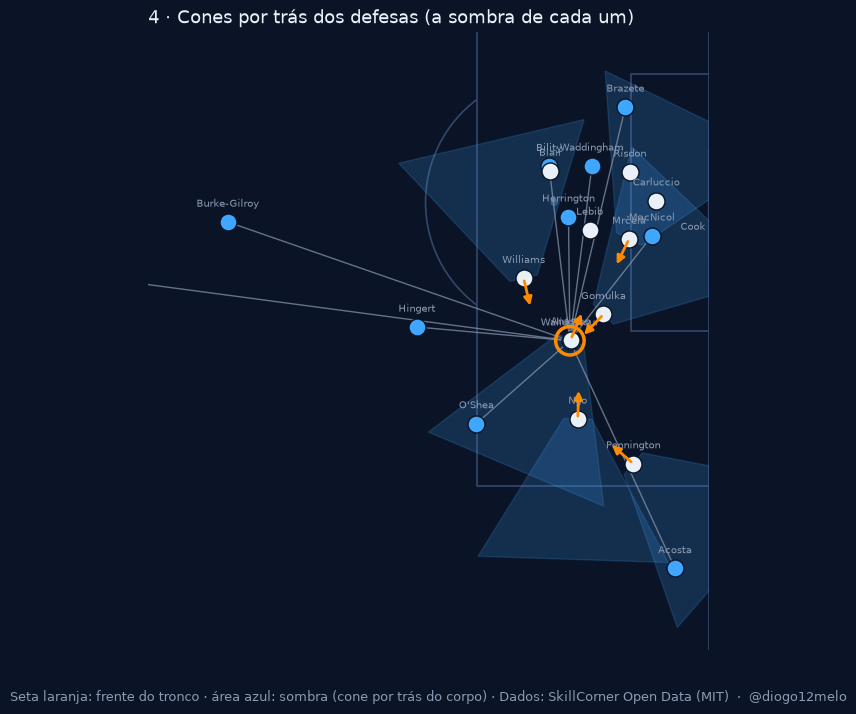

In [10]:
def contorno_do_cone(d, p=PADRAO):
    """Trapézio do cone: junto ao corpo com a largura do alcance, a abrir até ao comprimento."""
    ex, ey = np.cos(np.radians(d["orientacao"] + 180)), np.sin(np.radians(d["orientacao"] + 180))
    nx, ny = -ey, ex
    w0 = p.largura_junto_ao_corpo / 2
    w1 = w0 + p.comprimento_cone * np.tan(np.radians(p.angulo_cone / 2))
    base_ = np.array([d["x"], d["y"]])
    eixo, normal = np.array([ex, ey]), np.array([nx, ny])
    return np.array([base_ + w0 * normal, base_ - w0 * normal,
                     base_ + p.comprimento_cone * eixo - w1 * normal, base_ + p.comprimento_cone * eixo + w1 * normal])


fig, ax = base("4 · Cones por trás dos defesas (a sombra de cada um)")
elegiveis = defesas_frame[~defesas_frame["a_marcar"] & defesas_frame["orientacao"].notna()]
for _, d in elegiveis.iterrows():
    ax.add_patch(Polygon(contorno_do_cone(d), closed=True, facecolor=brand.colors["secondary"], alpha=0.18,
                         edgecolor=brand.colors["secondary"], lw=1, zorder=1))
    fx, fy = vetor(d["orientacao"])
    ax.annotate("", xy=(d["x"] + 2.2 * fx, d["y"] + 2.2 * fy), xytext=(d["x"], d["y"]), zorder=6,
                arrowprops={"arrowstyle": "-|>", "color": brand.colors["primary"], "lw": 2})
for _, r in recetores.iterrows():
    ax.plot([origem[0], r["x"]], [origem[1], r["y"]], color=brand.colors["text_muted"], lw=1, alpha=0.7, zorder=2)
guardar(fig, "4_cones", "Seta laranja: frente do tronco · área azul: sombra (cone por trás do corpo)")

### 2.5 Probabilidade de o passe chegar (D16)

Para cada defesa cuja sombra cobre a linha: a probabilidade de chegar a um ponto da linha antes da
bola, a partir da margem de tempo (segundos de avanço sobre a bola: tempo da bola desde o portador,
menos tempo de reação e de corrida do defesa: durante a reação o defesa continua à velocidade que trazia, calculada a partir das posições sobre 0,4 s, e só depois corre em linha reta a 5 m/s), numa curva logística com 0,45 s de incerteza, tomando o
melhor ponto da linha dentro do cone (D16, D19). Um defesa que chega tarde a todos os pontos recebe uma
probabilidade baixa; um que chega bem antes da bola, perto de 1.

**Bloqueio pelo corpo (D30, D34):** quanto mais perto do defesa a linha passa (dentro do cone), mais provável é a bola
bater-lhe no corpo, sem contar o tempo de reação: a probabilidade desse defesa é 1 a 0,3 m ou menos e desce
linearmente até 0 a 1,2 m. Vale a maior entre este bloqueio e a de chegar a tempo.

**Pressuposto para combinar vários defesas:** são independentes. O passe chega com probabilidade
`prod(1 − p_defesa)`; sem sombras, chega com probabilidade 1.

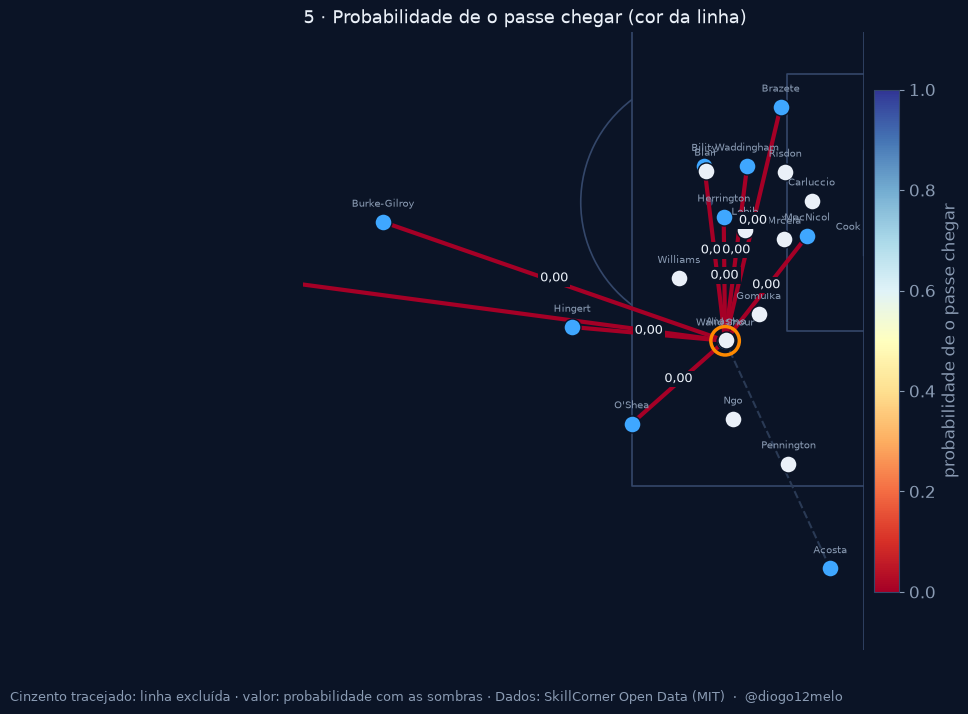

,Linha para,Defesa,p (chega à linha),Parte (xT)
0,M. Freke,J. Anasmo,1.000,0.000
1,J. O'Shea,J. Anasmo,1.000,0.000
2,J. Hingert,J. Anasmo,1.000,0.000
3,H. Bility,D. Williams,0.011,0.000
4,H. Bility,J. Anasmo,1.000,0.053
5,A. Burke-Gilroy,J. Anasmo,1.000,0.000
6,T. Waddingham,J. Anasmo,1.000,0.203
7,Q. MacNicol,T. Gomulka,0.524,0.051
8,Q. MacNicol,T. Mrčela,0.097,0.008
9,Q. MacNicol,J. Anasmo,1.000,0.143


In [11]:
fig, ax = base("5 · Probabilidade de o passe chegar (cor da linha)")
mapa = plt.get_cmap("RdYlBu")
avaliadas = linhas_frame[~linhas_frame["excluida"]].set_index("recetor")
for _, r in recetores.iterrows():
    if r["recetor"] in avaliadas.index:
        p_chegar = avaliadas.loc[r["recetor"], "p_chegar"]
        ax.plot([origem[0], r["x"]], [origem[1], r["y"]], color=mapa(p_chegar), lw=3, zorder=2)
        if avaliadas.loc[r["recetor"], "n_sombras"] > 0:
            ax.annotate(pt(p_chegar, 2), ((origem[0] + r["x"]) / 2, (origem[1] + r["y"]) / 2), fontsize=9,
                        ha="center", color=brand.colors["text"], zorder=6,
                        bbox={"facecolor": brand.colors["background"], "edgecolor": "none", "pad": 1.5})
    else:
        ax.plot([origem[0], r["x"]], [origem[1], r["y"]], color=brand.colors["neutral"], lw=1.5, ls="--", zorder=2)
barra = fig.colorbar(plt.cm.ScalarMappable(cmap=mapa), ax=ax, fraction=0.025, pad=0.01)
barra.set_label("probabilidade de o passe chegar", color=brand.colors["text_muted"])
barra.ax.tick_params(colors=brand.colors["text_muted"])
guardar(fig, "5_probabilidades", "Cinzento tracejado: linha excluída · valor: probabilidade com as sombras")
atrib_frame.assign(recetor=lambda t: t["recetor"].map(nome), defesa=lambda t: t["defesa"].map(nome)).rename(
    columns={"recetor": "Linha para", "defesa": "Defesa", "p_defesa": "p (chega à linha)", "shapley": "Parte (xT)"}).round(3)

### 2.6 Ameaça negada (D8)

`ameaça negada = perigo da linha × (1 − probabilidade de o passe chegar com as sombras)`. É a
descida na probabilidade de chegar, de 1 sem sombras para a probabilidade do passo anterior,
multiplicada pelo perigo.

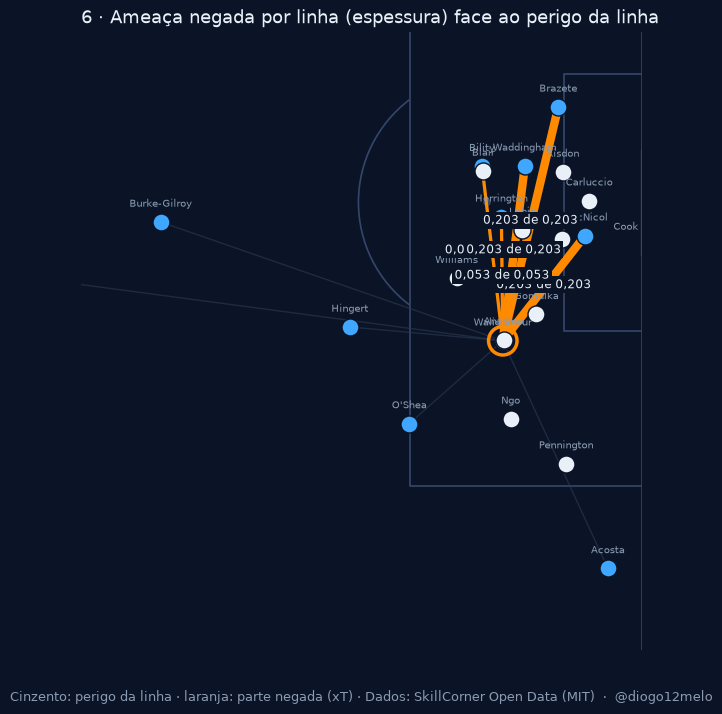

In [12]:
fig, ax = base("6 · Ameaça negada por linha (espessura) face ao perigo da linha")
maximo = max(avaliadas["valor_xt"].max(), 1e-9)
for _, r in recetores.iterrows():
    ax.plot([origem[0], r["x"]], [origem[1], r["y"]], color=brand.colors["neutral"], lw=1 + 5 * r["valor_xt"] / maximo,
            alpha=0.6, zorder=1)
    if r["recetor"] in avaliadas.index and avaliadas.loc[r["recetor"], "ameaca_negada"] > 0:
        negada = avaliadas.loc[r["recetor"], "ameaca_negada"]
        ax.plot([origem[0], r["x"]], [origem[1], r["y"]], color=brand.colors["primary"], lw=1 + 5 * negada / maximo, zorder=2)
        ax.annotate(f"{pt(negada, 3)} de {pt(r['valor_xt'], 3)}", ((origem[0] + r["x"]) / 2, (origem[1] + r["y"]) / 2),
                    fontsize=8.5, ha="center", color=brand.colors["text"], zorder=6,
                    bbox={"facecolor": brand.colors["background"], "edgecolor": "none", "pad": 1.5})
guardar(fig, "6_ameaca_negada", "Cinzento: perigo da linha · laranja: parte negada (xT)")

### 2.7 Repartição pelos defesas: valor de Shapley (D9)

Quando mais do que um defesa fecha a mesma linha, a ameaça negada reparte-se pelo valor de Shapley:
cada defesa recebe o que acrescenta, em média, sobre todas as ordens em que entram. As partes
somam o total da linha; com um só defesa, é o efeito com e sem ele.

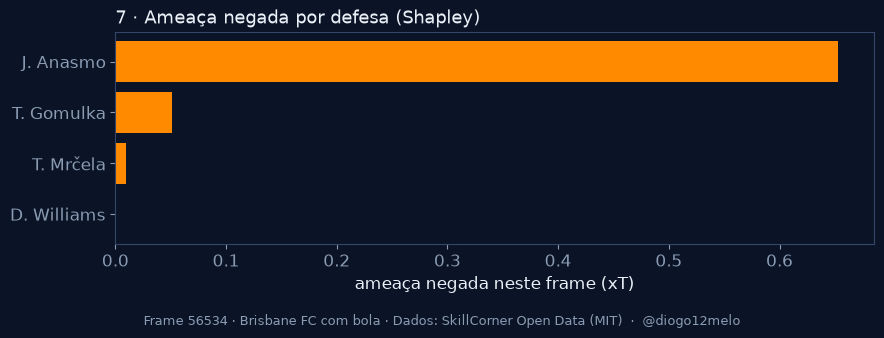

Linha para **H. Bility**: ameaça negada total 0,0531 xT; soma das partes 0,0531 xT.

,defesa,p_defesa,shapley
3,D. Williams,0.011,0.0003
4,J. Anasmo,1.000,0.0528


In [13]:
por_defesa = atrib_frame.groupby("defesa")["shapley"].sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 0.5 * max(len(por_defesa), 3) + 1.4))
ax.barh([nome[j] for j in por_defesa.index], por_defesa.values, color=brand.colors["primary"])
ax.set_xlabel("ameaça negada neste frame (xT)")
ax.set_title("7 · Ameaça negada por defesa (Shapley)", loc="left", color=brand.colors["text"], fontsize=13)
credito(fig, f"Frame {FRAME} · {com_bola} com bola")
fig.savefig(SAIDA / "fase4_7_shapley.png", dpi=150, facecolor=brand.colors["background"])
plt.show()

duas = atrib_frame.groupby("recetor").filter(lambda g: len(g) >= 2)
if not duas.empty:
    linha_exemplo = duas["recetor"].iloc[0]
    total = linhas_frame.set_index("recetor").loc[linha_exemplo, "ameaca_negada"]
    exemplo = duas[duas["recetor"] == linha_exemplo]
    display(Markdown(f"Linha para **{nome[linha_exemplo]}**: ameaça negada total {pt(total, 4)} xT; "
                     f"soma das partes {pt(exemplo['shapley'].sum(), 4)} xT."))
    display(exemplo.assign(defesa=lambda t: t["defesa"].map(nome))[["defesa", "p_defesa", "shapley"]].round(4))

## 3. O jogo inteiro

Os mesmos passos aplicados a todos os frames do jogo 1925299 (posses de 5 medições por segundo, D11),
com os parâmetros da secção 1. As tabelas seguintes descrevem o resultado; não o interpretam.

In [14]:
resumo = agregacao.resumo_do_jogo(J["linhas"])
print(f"Linhas de passe: {resumo['linhas']} · avaliadas {resumo['avaliadas']} · "
      f"excluídas {resumo['excluidas']} ({pt(resumo['pct_excluidas'])} %): "
      f"sem pose {resumo['excl_sem_pose']}, fora de jogo {resumo['excl_fora_de_jogo']}, "
      f"cruzamento {resumo['excl_cruzamento']}")
print(f"Ameaça disponível nas linhas avaliadas: {pt(resumo['disponivel'], 1)} xT · "
      f"ameaça negada: {pt(resumo['negada'], 1)} xT ({pt(resumo['pct_negada'])} %)")
print(f"Frames: {J['linhas']['frame'].nunique()} · posses: {J['linhas']['posse_id'].nunique()}")


Linhas de passe: 89150 · avaliadas 59327 · excluídas 29823 (33,5 %): sem pose 26005, fora de jogo 2902, cruzamento 916
Ameaça disponível nas linhas avaliadas: 266,1 xT · ameaça negada: 124,8 xT (46,9 %)
Frames: 8915 · posses: 924


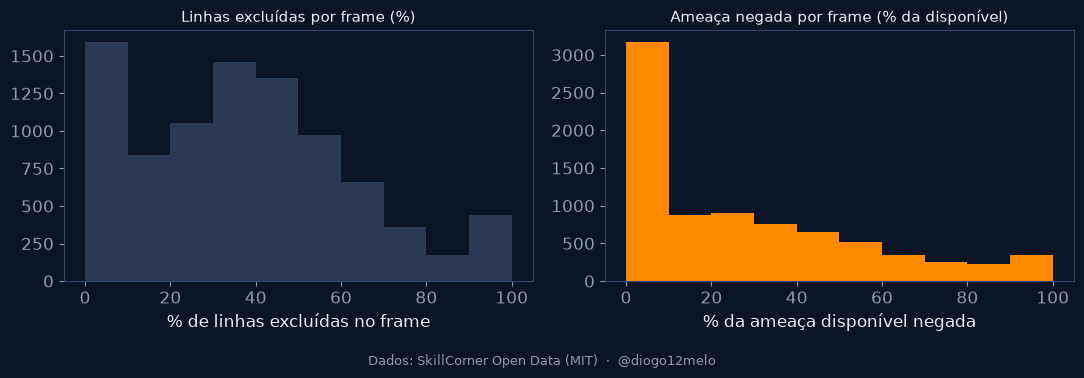

In [15]:
lances = agregacao.por_lance(J["linhas"])
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
a.hist(lances["n_excluidas"] / lances["n_linhas"] * 100, bins=np.arange(0, 105, 10), color=brand.colors["neutral"])
a.set_title("Linhas excluídas por frame (%)", fontsize=11)
a.set_xlabel("% de linhas excluídas no frame")
b.hist(lances["pct_negada"].dropna(), bins=np.arange(0, 105, 10), color=brand.colors["primary"])
b.set_title("Ameaça negada por frame (% da disponível)", fontsize=11)
b.set_xlabel("% da ameaça disponível negada")
credito(fig)
fig.savefig(SAIDA / "fase4_distribuicao_jogo.png", dpi=150, facecolor=brand.colors["background"])
plt.show()

### 3.1 Por lance (D17)

Os 10 frames com mais ameaça negada, com a ameaça disponível e a percentagem negada.

In [16]:
lances_com_nomes = lances.merge(
    J["linhas"].groupby("frame")["portador"].first().rename("portador").reset_index(), on="frame")
lances_com_nomes["portador"] = lances_com_nomes["portador"].map(nome)
lances_com_nomes.nlargest(10, "negada")[
    ["frame", "portador", "n_linhas", "n_sem_pose", "n_fora_de_jogo", "n_cruzamento", "disponivel", "negada", "pct_negada"]].round(3).rename(columns={
        "n_linhas": "linhas", "n_sem_pose": "sem pose",
        "n_fora_de_jogo": "fora de jogo", "n_cruzamento": "cruzamento", "disponivel": "disponível (xT)", "negada": "negada (xT)",
        "pct_negada": "% negada"}).style.hide(axis="index")

frame,portador,linhas,sem pose,fora de jogo,cruzamento,disponível (xT),negada (xT),% negada
56508,N. Acosta,10,0,0,0,0.932000,0.842000,90.313000
56506,N. Acosta,10,0,0,0,0.932000,0.782000,83.866000
56504,N. Acosta,10,0,0,0,0.985000,0.775000,78.714000
56502,N. Acosta,10,0,0,0,0.985000,0.762000,77.388000
56534,Walid Shour,10,0,1,0,0.714000,0.714000,100.000000
56500,N. Acosta,10,0,0,0,0.985000,0.710000,72.118000
56498,N. Acosta,10,0,0,0,0.985000,0.680000,69.079000
56546,J. O'Shea,10,0,0,0,0.714000,0.665000,93.140000
50574,J. Brazete,10,0,0,0,0.623000,0.549000,88.148000
56536,Walid Shour,10,0,1,0,0.714000,0.547000,76.612000


### 3.2 Por jogador (D17)

Soma, sobre as posses, da média por posse da ameaça negada (xT) e % da ameaça disponível negada
enquanto o jogador esteve em campo. Com dois jogos as tabelas são ilustrativas, não rankings; a
comparação faz-se sempre dentro da posição.

In [17]:
def tabela_por_jogador(J):
    presenca = J["defesas"][["frame", "posse_id", "jogador"]]
    lances_ = agregacao.por_lance(J["linhas"])
    por_posse = agregacao.por_posse_e_defesa(J["atribuicoes"], presenca, lances_)
    t = agregacao.por_jogador(por_posse, J["jogadores"])
    t["equipa"] = t["equipa"].map(J["equipas"])
    return t


por_jogador = tabela_por_jogador(J)
por_jogador[["nome", "equipa", "posicao", "posses", "negada", "pct_negada"]].round(2).rename(columns={
    "nome": "Jogador", "equipa": "Equipa", "posicao": "Posição", "posses": "Posses", "negada": "Negada (xT)",
    "pct_negada": "% negada"}).style.hide(axis="index")

Jogador,Equipa,Posição,Posses,Negada (xT),% negada
N. Pennington,Perth Glory,LM,585,2.190000,10.330000
T. Gomulka,Perth Glory,RM,585,1.510000,7.140000
T. Mrčela,Perth Glory,LCB,585,0.990000,4.690000
D. Williams,Perth Glory,CF,552,0.860000,4.350000
A. Lebib,Perth Glory,RCB,585,0.780000,3.680000
J. Risdon,Perth Glory,RB,585,0.730000,3.430000
J. Carluccio,Perth Glory,RW,202,0.620000,6.170000
J. Anasmo,Perth Glory,LW,114,0.460000,7.140000
R. Warland,Perth Glory,LB,471,0.440000,3.000000
T. Ostler,Perth Glory,RW,383,0.390000,3.520000


## 4. Dois jogos lado a lado

O segundo jogo com pose (1996435, Sydney FC – Adelaide United) segue o mesmo caminho, **sem alterar
nenhum parâmetro**: descarregar os dados, preparar a tabela da fase 3 e calcular a métrica.

```
uv run python -m footy.ingest.skillcorner --jogo 1996435 --tracking --pose
uv run python projects/cover_shadow/preparar_dados.py --jogo 1996435
uv run python projects/cover_shadow/calcular_metrica.py --jogo 1996435
```

In [18]:
tem_segundo = all(c.exists() for c in caminhos(JOGO_2))
if tem_segundo:
    J2 = jogo_completo(JOGO_2)
    print(f"{J2['match']['home_team']['short_name']} – {J2['match']['away_team']['short_name']}")
else:
    print("Jogo 1996435 ainda não calculado: os comandos acima geram as tabelas necessárias.")

Sydney FC – Adelaide United


In [19]:
def linha_de_comparacao(J):
    r = agregacao.resumo_do_jogo(J["linhas"])
    t = J["tabela"]
    defesas_ = J["defesas"]
    return {
        "Frames em posse": t["frame"].nunique(), "Posses": J["linhas"]["posse_id"].nunique(),
        "Defesas com pose (%)": 100 * defesas_["orientacao"].notna().mean(),
        "Defesas a marcar (%)": 100 * defesas_["a_marcar"].mean(),
        "Linhas de passe": r["linhas"], "Linhas avaliadas": r["avaliadas"],
        "Linhas excluídas (%)": r["pct_excluidas"],
        "  sem pose": r["excl_sem_pose"], "  fora de jogo": r["excl_fora_de_jogo"],
        "  cruzamento": r["excl_cruzamento"], "Ameaça disponível (xT)": r["disponivel"],
        "Ameaça negada (xT)": r["negada"], "Ameaça negada (%)": r["pct_negada"],
        "Linhas com sombra (%)": 100 * (J["linhas"]["n_sombras"] > 0).sum() / r["avaliadas"],
        "Defesas por linha com sombra": J["linhas"].loc[J["linhas"]["n_sombras"] > 0, "n_sombras"].mean(),
    }


jogos = {f"{J['match']['home_team']['short_name']} – {J['match']['away_team']['short_name']}": J}
if tem_segundo:
    jogos[f"{J2['match']['home_team']['short_name']} – {J2['match']['away_team']['short_name']}"] = J2
comparacao = pd.DataFrame({k: linha_de_comparacao(v) for k, v in jogos.items()})
comparacao.round(1)

,Brisbane FC – Perth Glory,Sydney FC – Adelaide United
Frames em posse,8915.0,8145.0
Posses,924.0,872.0
Defesas com pose (%),68.5,78.1
Defesas a marcar (%),23.1,22.7
Linhas de passe,89150.0,81450.0
Linhas avaliadas,59327.0,60636.0
Linhas excluídas (%),33.5,25.6
sem pose,26005.0,17425.0
fora de jogo,2902.0,2788.0
cruzamento,916.0,601.0


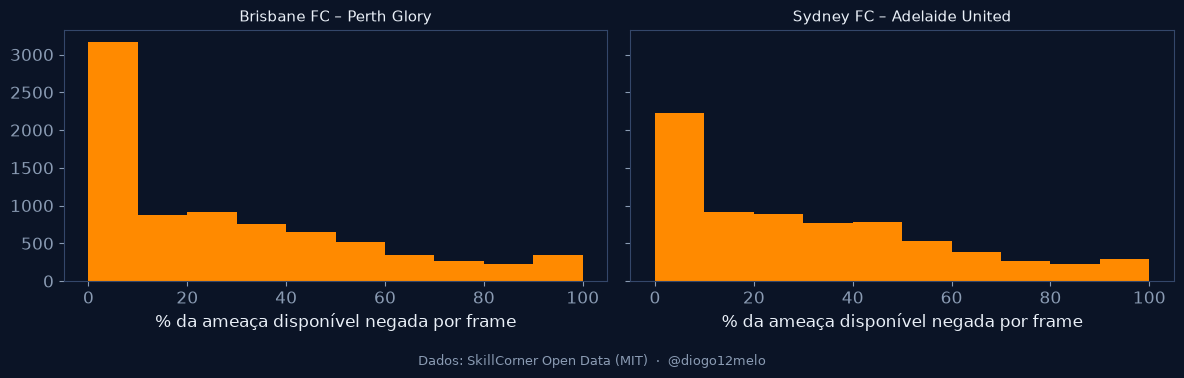

In [20]:
if tem_segundo:
    fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
    for ax, (titulo, jogo_) in zip(eixos, jogos.items()):
        l_ = agregacao.por_lance(jogo_["linhas"])
        ax.hist(l_["pct_negada"].dropna(), bins=np.arange(0, 105, 10), color=brand.colors["primary"])
        ax.set_title(titulo, fontsize=11)
        ax.set_xlabel("% da ameaça disponível negada por frame")
    credito(fig)
    fig.savefig(SAIDA / "fase4_dois_jogos.png", dpi=150, facecolor=brand.colors["background"])
    plt.show()

In [21]:
if tem_segundo:
    t2 = tabela_por_jogador(J2)
    display(Markdown(f"**{J2['match']['home_team']['short_name']} – {J2['match']['away_team']['short_name']}** · por jogador"))
    display(t2[["nome", "equipa", "posicao", "posses", "negada", "pct_negada"]].round(2).rename(columns={
        "nome": "Jogador", "equipa": "Equipa", "posicao": "Posição", "posses": "Posses", "negada": "Negada (xT)",
        "pct_negada": "% negada"}).style.hide(axis="index"))

**Sydney FC – Adelaide United** · por jogador

Jogador,Equipa,Posição,Posses,Negada (xT),% negada
E. Alagich,Adelaide United,LDM,466,1.320000,8.840000
J. Barnett,Adelaide United,RDM,332,0.900000,8.010000
Léo Sena,Sydney FC,LDM,406,0.660000,6.430000
P. Kikianis,Adelaide United,LCB,466,0.650000,4.370000
F. Talladira,Adelaide United,LB,466,0.640000,4.300000
J. Yull,Adelaide United,LW,441,0.520000,3.560000
S. Mauk,Adelaide United,AM,393,0.480000,3.460000
D. Pierias,Adelaide United,RB,466,0.460000,3.100000
Z. Clough,Adelaide United,RW,441,0.420000,2.850000
C. Hollman,Sydney FC,RDM,406,0.410000,4.050000


### 4.1 Por zona do campo e por fase defensiva (D32)

A ameaça negada somada por grupo de lances (frames de 0,2 s com pelo menos uma linha avaliada): `% negada` =
negada / disponível nesses lances. A **zona** é a da posse (terço e corredor onde começou, etiquetas da SkillCorner,
como em D27); a **fase** é a fase defensiva dos `phases_of_play` da SkillCorner (`team_out_of_possession_phase_type`)
em que o frame cai. As linhas excluídas (fora de jogo, cruzamento, sem pose) ficam fora, como em todo o notebook.
Descrição, sem leitura: com dois jogos e grupos de tamanhos muito diferentes, os números servem para ver a distribuição.

In [22]:
ROTULOS = {
    "attacking_third": "terço ofensivo", "middle_third": "terço médio", "defensive_third": "terço defensivo",
    "wide_left": "lateral esquerdo", "half_space_left": "meio-espaço esquerdo", "center": "centro",
    "half_space_right": "meio-espaço direito", "wide_right": "lateral direito",
    "high_block": "bloco alto", "medium_block": "bloco médio", "low_block": "bloco baixo", "chaotic": "caótica",
    "defending_direct": "defesa de jogo direto", "defending_set_play": "bola parada",
    "defending_quick_break": "contra-ataque", "defending_transition": "transição defensiva"}


def por_contexto(J, por):
    contexto = agregacao.contexto_dos_frames(J["tabela"], sc.ler_fases(J["jogo"]))
    return agregacao.por_zona_ou_fase(agregacao.por_lance(J["linhas"]), contexto, por)


def mostrar_por_contexto(por, titulo):
    partes = []
    for nome_jogo, jogo_ in jogos.items():
        t = por_contexto(jogo_, por)
        t[por] = t[por].map(ROTULOS).fillna("sem fase")
        partes.append(t.assign(Jogo=nome_jogo))
    t = pd.concat(partes, ignore_index=True)
    display(Markdown(f"**{titulo}**"))
    display(t[["Jogo", por, "lances", "disponivel", "negada", "pct_negada"]].round(2).rename(columns={
        por: titulo.split(" por ")[-1].capitalize(), "lances": "Lances", "disponivel": "Disponível (xT)",
        "negada": "Negada (xT)", "pct_negada": "% negada"}).style.hide(axis="index"))


for por, titulo in [("terco", "Ameaça negada por terço da posse"), ("corredor", "Ameaça negada por corredor da posse"),
                    ("fase", "Ameaça negada por fase defensiva")]:
    mostrar_por_contexto(por, titulo)

**Ameaça negada por terço da posse**

Jogo,Terço da posse,Lances,Disponível (xT),Negada (xT),% negada
Brisbane FC – Perth Glory,terço ofensivo,2041,166.750000,94.590000,56.720000
Brisbane FC – Perth Glory,terço médio,3746,74.170000,24.500000,33.030000
Brisbane FC – Perth Glory,terço defensivo,2781,25.160000,5.730000,22.780000
Sydney FC – Adelaide United,terço ofensivo,1960,133.730000,60.140000,44.970000
Sydney FC – Adelaide United,terço médio,3206,77.240000,26.380000,34.150000
Sydney FC – Adelaide United,terço defensivo,2571,28.370000,7.820000,27.570000


**Ameaça negada por corredor da posse**

Jogo,Corredor da posse,Lances,Disponível (xT),Negada (xT),% negada
Brisbane FC – Perth Glory,lateral direito,1997,73.030000,38.680000,52.970000
Brisbane FC – Perth Glory,meio-espaço direito,1596,56.780000,25.740000,45.340000
Brisbane FC – Perth Glory,meio-espaço esquerdo,1352,47.790000,22.770000,47.650000
Brisbane FC – Perth Glory,lateral esquerdo,1600,43.570000,20.320000,46.650000
Brisbane FC – Perth Glory,centro,2023,44.910000,17.290000,38.510000
Sydney FC – Adelaide United,lateral direito,2005,65.410000,27.770000,42.460000
Sydney FC – Adelaide United,meio-espaço esquerdo,1248,46.060000,19.660000,42.670000
Sydney FC – Adelaide United,meio-espaço direito,1134,50.960000,18.270000,35.860000
Sydney FC – Adelaide United,lateral esquerdo,1501,42.760000,18.090000,42.310000
Sydney FC – Adelaide United,centro,1849,34.170000,10.560000,30.910000


**Ameaça negada por fase defensiva**

Jogo,Fase defensiva,Lances,Disponível (xT),Negada (xT),% negada
Brisbane FC – Perth Glory,bloco baixo,2707,153.800000,74.570000,48.480000
Brisbane FC – Perth Glory,contra-ataque,301,29.910000,17.010000,56.880000
Brisbane FC – Perth Glory,bloco médio,3284,41.750000,11.840000,28.370000
Brisbane FC – Perth Glory,bola parada,83,17.160000,11.750000,68.510000
Brisbane FC – Perth Glory,caótica,543,9.890000,6.490000,65.600000
Brisbane FC – Perth Glory,bloco alto,1548,11.980000,2.380000,19.850000
Brisbane FC – Perth Glory,transição defensiva,82,1.360000,0.730000,53.620000
Brisbane FC – Perth Glory,defesa de jogo direto,16,0.220000,0.050000,21.930000
Brisbane FC – Perth Glory,sem fase,4,0.010000,0.000000,0.000000
Sydney FC – Adelaide United,bloco baixo,2231,117.520000,50.920000,43.330000


### 4.2 v3.1: a versão final acrescenta o limite de 35 m (D37, D43)

A **v3.1** é a v3 mais a exclusão das linhas com mais de 35 m (D37): `Parametros.comprimento_maximo_linha = 35.0`
em `metrica/parametros.py` (`PADRAO` é a v3.1; `PADRAO_V3` e `PADRAO_V2` continuam a reproduzir as anteriores). Uma linha com mais de 35 m
fica excluída com o motivo `mais_de_35m`, depois de verificados os outros três (fora de jogo, cruzamento, sem pose), e deixa de contar para a ameaça
disponível e para a negada. Nas linhas até 35 m a v3.1 é exatamente a v3. O valor da sombra apresenta-se como **índice de fecho da linha**,
não como probabilidade calibrada de o passe chegar (D43). Os números vêm de `outputs/cover_shadow/artigo_v31.json` (`numeros_v31.py`).

In [23]:
import json

import avaliacao as av
from metrica.parametros import PADRAO as PADRAO_V31

V31 = json.loads((SAIDA / "artigo_v31.json").read_text(encoding="utf-8"))
print(f"comprimento_maximo_linha: v3.1 = {PADRAO_V31.comprimento_maximo_linha} m; v3 = {PADRAO.comprimento_maximo_linha}")
print(V31["definicao"])

linhas_tab = []
for j in (JOGO, JOGO_2):
    v3, _ = av.ler_variante(j, "base", av.PASTAS["v3"])
    v31, _ = av.ler_variante(j, "base", av.PASTAS["v3_1"])
    for nome, t in (("v3", v3), ("v3.1", v31)):
        a = t[~t["excluida"]]
        linhas_tab.append({"jogo": j, "versão": nome, "linhas": len(t), "avaliadas": len(a),
                           **{f"excl. {m}": n for m, n in agregacao.excluidas_por_motivo(t).items()},
                           "perigo (xT)": round(a["valor_xt"].sum(), 2), "negada (xT)": round(a["ameaca_negada"].sum(), 2),
                           "% negada": round(100 * a["ameaca_negada"].sum() / a["valor_xt"].sum(), 1)})
display(pd.DataFrame(linhas_tab))

comprimento_maximo_linha: v3.1 = 35.0 m; v3 = None
{'versao': 'v3.1 (D43)', 'regra': 'v3 + exclusão das linhas com mais de 35 m (D37)', 'comprimento_maximo_linha_m': 35.0, 'valor_da_sombra': 'índice de fecho da linha, não probabilidade calibrada de o passe chegar'}


,jogo,versão,linhas,avaliadas,excl. sem_pose,excl. fora_de_jogo,excl. cruzamento,excl. mais_de_35m,perigo (xT),negada (xT),% negada
0,1925299,v3,89150,59327,26005,2902,916,0,266.08,124.82,46.9
1,1925299,v3.1,89150,47763,26005,2902,916,11564,237.27,108.74,45.8
2,1996435,v3,81450,60636,17425,2788,601,0,239.35,94.35,39.4
3,1996435,v3.1,81450,48542,17425,2788,601,12094,210.04,78.68,37.5


Nas linhas até 35 m a v3.1 coincide com a v3 (mesma exclusão, mesma `p_chegar`, mesma `ameaca_negada`); todas as de mais de 35 m ficam excluídas.
Ameaça negada (xT) por banda de comprimento da linha, dois jogos juntos:

In [24]:
bandas = {"v3": pd.DataFrame(V31["negada_por_comprimento"]["v3"]), "v3.1": pd.DataFrame(V31["negada_por_comprimento"]["v3_1"])}
t = bandas["v3"].merge(bandas["v3.1"], on=["de_m", "ate_m"], suffixes=(" v3", " v3.1"))
t["banda (m)"] = [f"{a:.0f}–{b:.0f}" if b < 1000 else f"> {a:.0f}" for a, b in zip(t["de_m"], t["ate_m"])]
display(t[["banda (m)", "linhas v3", "negada v3", "pct_do_total_negada v3", "linhas v3.1", "negada v3.1", "pct_do_total_negada v3.1"]].round(2))

for j in (JOGO, JOGO_2):
    t3 = av.ler_variante(j, "base", av.PASTAS["v3"])[0]
    t31 = av.ler_variante(j, "base", av.PASTAS["v3_1"])[0]
    m = t3.merge(t31, on=["frame", "recetor"], suffixes=("_v3", "_v31"))
    ate = m[m["comprimento"] <= 35]
    print(f"{j}: {len(ate)} linhas até 35 m; maior diferença em p_chegar {np.nanmax(np.abs(ate.p_chegar_v3 - ate.p_chegar_v31)):.1f}, "
          f"em ameaca_negada {np.nanmax(np.abs(ate.ameaca_negada_v3 - ate.ameaca_negada_v31)):.1f}; "
          f"linhas de mais de 35 m não excluídas na v3.1: {int((~m[m['comprimento'] > 35]['excluida_v31']).sum())}")

,banda (m),linhas v3,negada v3,pct_do_total_negada v3,linhas v3.1,negada v3.1,pct_do_total_negada v3.1
0,0–10,13795,10.89,4.97,13795,10.89,5.81
1,10–20,39658,61.76,28.18,39658,61.76,32.96
2,20–30,31644,86.04,39.26,31644,86.04,45.91
3,30–35,11208,28.73,13.11,11208,28.73,15.33
4,35–45,13827,22.75,10.38,0,0.00,0.00
5,> 45,9831,9.00,4.11,0,0.00,0.00


1925299: 64747 linhas até 35 m; maior diferença em p_chegar 0.0, em ameaca_negada 0.0; linhas de mais de 35 m não excluídas na v3.1: 0


1996435: 59926 linhas até 35 m; maior diferença em p_chegar 0.0, em ameaca_negada 0.0; linhas de mais de 35 m não excluídas na v3.1: 0


## 5. Síntese da fase

- A Cover Shadow Value calcula-se em nove passos, cada um uma função curta em `metrica/`, com todos
  os parâmetros em `metrica/parametros.py`. O número do jogo é sempre um parâmetro do código.
- O perigo de cada linha é o ganho de xT na grelha 12 × 8 de Karun Singh, lida no sentido de ataque
  da equipa. A sombra é um cone por trás do tronco, com a largura do alcance junto ao corpo. O alcance
  entra só na probabilidade de o passe chegar (tempo da bola contra tempo do defesa), que combina os
  defesas como independentes, e a ameaça negada reparte-se pelo valor de Shapley (as partes somam o total da linha).
- Ficam de fora e são contadas por motivo as linhas para colegas em fora de jogo (D26), os cruzamentos
  (D27) e as linhas em que um defesa que a poderia afetar não tem pose (D13); a secção 3 mostra quantas
  são e a secção 4 compara-as entre os dois jogos.
- Mudanças desta versão, vindas das duas revisões por um treinador (D25–D34): guarda-redes sem sombra nem marcação,
  pressão distinta de marcação, marcação com continuidade (entra a 4 m, com 1 m de tolerância no lado da baliza,
  e sai a 5 m) e bloqueio pelo corpo gradual (1 até 0,3 m, 0 a 1,2 m da linha). Os limiares novos (A11) são valores
  de partida.
- A secção 4.1 divide a ameaça negada por zona do campo e fase defensiva (D32), sem a interpretar.
- O mesmo código e os mesmos parâmetros correram nos dois jogos com pose. Os resultados por jogador
  são ilustrativos (dois jogos), não classificações.
- Limitações a declarar: o xT é da Premier League e ignora o contexto; não se estima a probabilidade
  de o portador escolher cada passe; os defesas intercetam de forma independente; a probabilidade
  de chegar usa velocidades constantes e linhas retas; os parâmetros são valores de partida, por testar
  na avaliação (fase 5).